In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor

In [32]:
df = pd.read_csv("../data_processed/final_data.csv")

In [33]:
df.head()

,id,property_type,parking,renovation,windows,ceiling_height,garbage_chute,currency,price,total_area,...,balconies,loggias,combined_bathrooms,separate_bathrooms,children_allowed,pets_allowed,furniture,washing_machine,dishwasher,air_conditioner
0,271271157,0,5,2,0,3.0,1,0,500000.0,200.0,...,1.0,1.0,1.0,1.0,1,1,1,1,1,1
1,271634126,0,5,2,3,3.5,2,0,500000.0,198.0,...,1.0,1.0,2.0,1.0,1,0,1,1,1,1
2,271173086,0,5,3,3,3.2,0,0,500000.0,200.0,...,1.0,1.0,3.0,1.0,1,0,1,1,1,1
3,272197456,0,5,3,3,3.2,0,0,400000.0,170.0,...,1.0,1.0,3.0,1.0,0,1,1,1,1,1
4,273614615,0,0,3,3,3.9,1,0,225000.0,58.0,...,1.0,1.0,2.0,1.0,0,0,1,1,1,0


In [34]:
df.dtypes

id                       int64
property_type            int64
parking                  int64
renovation               int64
windows                  int64
ceiling_height         float64
garbage_chute            int64
currency                 int64
price                  float64
total_area             float64
price_per_sqm          float64
rooms                  float64
room_layout              int64
metro_walk_minutes     float64
floor                    int64
total_floors             int64
passenger_elevators    float64
freight_elevators      float64
balconies              float64
loggias                float64
combined_bathrooms     float64
separate_bathrooms     float64
children_allowed         int64
pets_allowed             int64
furniture                int64
washing_machine          int64
dishwasher               int64
air_conditioner          int64
dtype: object

In [35]:
print("Пропуски:", df.isna().sum().sum())
print("Полные дубликаты:", df.duplicated().sum())
print("Дубликаты ID:", df["id"].duplicated().sum())

Пропуски: 0
Полные дубликаты: 0
Дубликаты ID: 0


In [36]:
df.to_csv("data_3.csv", index=False)

In [37]:
df_check = pd.read_csv("data_3.csv")

In [38]:
print("Размер таблицы:", df_check.shape)
print("Пропуски:", df_check.isna().sum().sum())
print("Дубликаты ID:", df_check["id"].duplicated().sum())

Размер таблицы: (23344, 28)
Пропуски: 0
Дубликаты ID: 0


In [39]:
print(df.columns)

Index(['id', 'property_type', 'parking', 'renovation', 'windows',
       'ceiling_height', 'garbage_chute', 'currency', 'price', 'total_area',
       'price_per_sqm', 'rooms', 'room_layout', 'metro_walk_minutes', 'floor',
       'total_floors', 'passenger_elevators', 'freight_elevators', 'balconies',
       'loggias', 'combined_bathrooms', 'separate_bathrooms',
       'children_allowed', 'pets_allowed', 'furniture', 'washing_machine',
       'dishwasher', 'air_conditioner'],
      dtype='str')


In [40]:
X = df.drop(columns=["id", "price", "price_per_sqm"])
y = df["price"]

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [42]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](25,)","[ 0. , -80.14,-3866.53,...,-5524.05, 4061.98, 8287.3 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](25,)","['property_type','parking','renovation',...,'washing_machine','dishwasher', 'air_conditioner']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-6.118e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,25
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(23)


In [43]:
y_pred = model.predict(X_test)

In [44]:
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
print(f"MAPE: {mape:.2f}%")

MAPE: 39.35%


In [45]:
model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

mape_rf = mean_absolute_percentage_error(y_test, y_pred_rf) * 100

print(f"MAPE Random Forest: {mape_rf:.2f}%")

MAPE Random Forest: 23.51%


In [46]:
comparison = pd.DataFrame({
    "Реальная цена": y_test,
    "Предсказанная цена": y_pred_rf
})

comparison.head(10)

,Реальная цена,Предсказанная цена
13544,45000.0,38088.990000
7809,50000.0,47000.000000
20750,35000.0,42290.000000
13359,80000.0,88124.960000
12843,250000.0,247050.000000
247,32000.0,30488.333333
9437,69000.0,63761.600000
2707,70000.0,81462.980000
3441,90000.0,78340.000000
3426,110000.0,119046.000000


In [47]:
import joblib

joblib.dump(model_rf, "rent_price_model.pkl")

['rent_price_model.pkl']

In [48]:
print(f"Linear Regression MAPE: {mape:.2f}%")
print(f"Random Forest MAPE: {mape_rf:.2f}%")

Linear Regression MAPE: 39.35%
Random Forest MAPE: 23.51%


## Результаты моделирования

Были обучены и сравнены две модели:
- Linear Regression: MAPE = 39,35%.
- Random Forest: MAPE = 23,51%.

Лучшая модель — Random Forest. Она достигла целевого значения MAPE менее 30%.

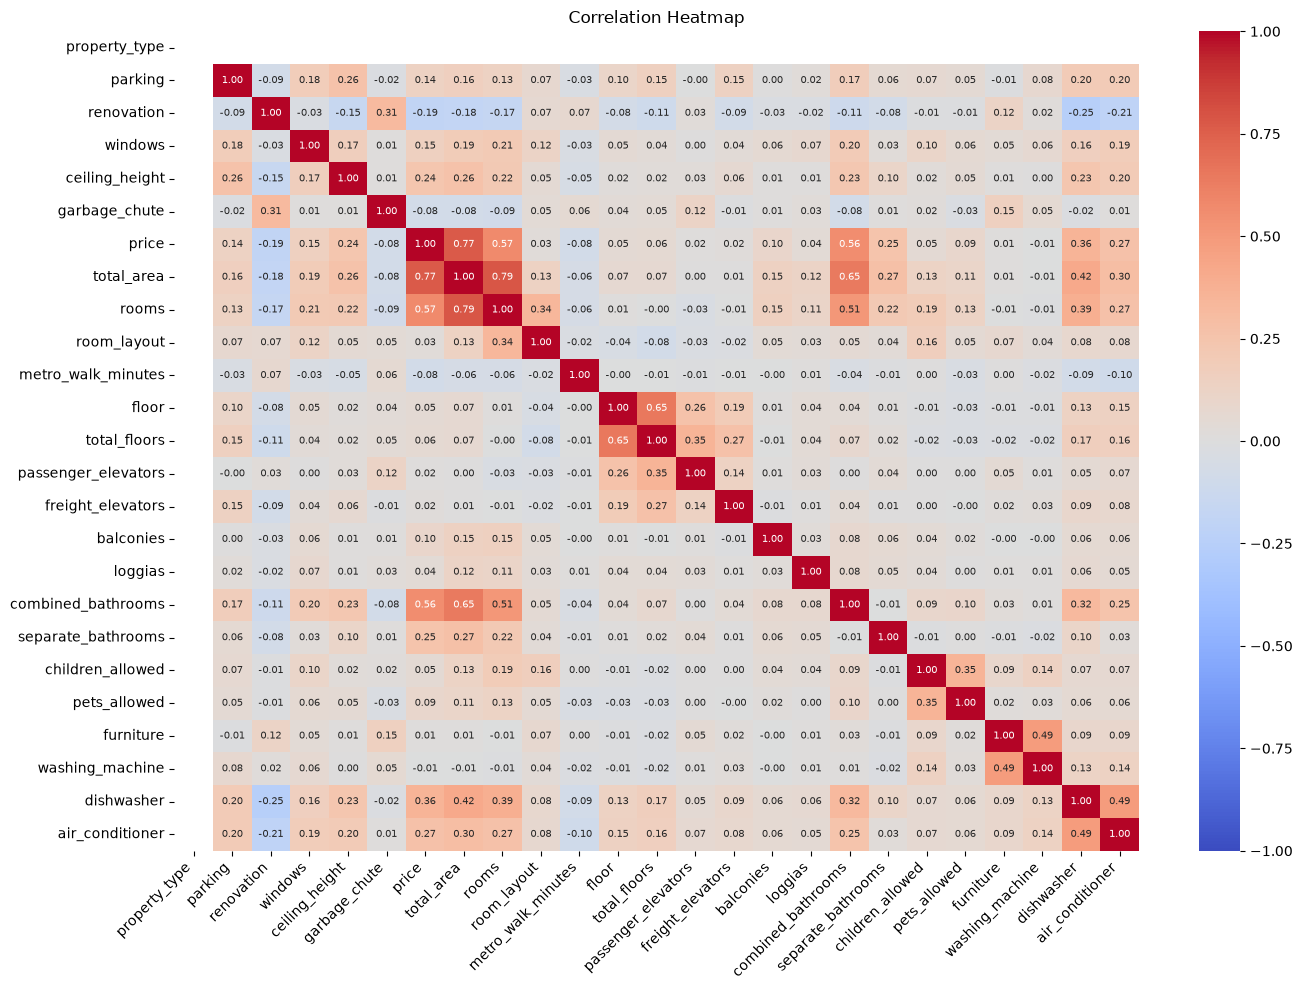

In [49]:
df_corr = df.drop(
    columns=["id", "price_per_sqm", "currency"],
    errors="ignore"
)

corr = df_corr.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("heatmap.png", dpi=150, bbox_inches="tight")
plt.show()